# TD6 — TP3: EuroSAT
## 1. Arquitectura custom y entrenamiento desde cero

Clasificamos imágenes RGB de uso del suelo en diez clases con PyTorch.
Tomamos de la práctica 16 la estructura Conv2d → activación → pooling y el loop
de entrenamiento; de la práctica 17, las transformaciones separadas para entrenamiento
y evaluación. La práctica 18 aborda autoencoders y no es necesaria para este punto.

Este notebook prepara el punto 1 completo. Las métricas y conclusiones deben completarse
después de ejecutar el entrenamiento: no se incluyen resultados inventados.

### Preparación
Ejecutar las celdas en orden. Se necesitan `torch`, `torchvision`, `numpy`,
`matplotlib`, `Pillow` y `tqdm`. En un entorno que no los tenga, instalar con
`%pip install torch torchvision numpy matplotlib pillow tqdm` y reiniciar el kernel.
Los archivos se leen por lotes; no se carga el dataset completo en memoria.

In [ ]:
import csv
import json
import random
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from tqdm.auto import tqdm

Dispositivo: cpu


In [ ]:
#semilla
random.seed(22)
np.random.seed(22)
torch.manual_seed(22)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(22)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

In [ ]:
#Dispositivo
device = torch.device('cuda' if torch.cuda.is_available() else
                      'mps' if torch.backends.mps.is_available() else 'cpu')
print('Dispositivo:', device)

In [8]:
#Directorios
DATA_DIR = Path('EuroSAT')
OUTPUT_DIR = Path.cwd() / 'resultados_punto1'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
#Hiperparametros -> VER
BATCH_SIZE = 64
EPOCHS = 25
LR = 1e-3
GRAD_EPOCHS = 3
# En notebooks de Windows usamos 0 para evitar problemas de multiprocessing.
NUM_WORKERS = 0

### Datos y particiones
Usamos los CSV provistos con esta copia de EuroSAT. No volvemos a dividir los datos.
Comprobamos que los conjuntos no compartan archivos y que las etiquetas coincidan
con `label_map.json`. El conjunto de test queda reservado para el punto 2.

La separación por archivos no garantiza independencia geográfica: recortes cercanos
podrían compartir información. Sin coordenadas no podemos verificar ese aspecto.

In [2]:
with (DATA_DIR / 'label_map.json').open(encoding='utf-8') as f:
    class_to_idx = json.load(f)
assert sorted(class_to_idx.values()) == list(range(10))
class_names = sorted(class_to_idx, key=class_to_idx.get)
num_classes = len(class_names)

def leer_split(nombre):
    with (DATA_DIR / nombre).open(encoding='utf-8-sig', newline='') as f:
        rows = list(csv.DictReader(f))
    muestras = []
    for row in rows:
        ruta = row['Filename'].replace('\\', '/')
        label = int(row['Label'])
        assert label == class_to_idx[row['ClassName']]
        assert (DATA_DIR / ruta).is_file(), ruta
        muestras.append((ruta, label))
    assert len(muestras) > 0
    assert len({r for r, _ in muestras}) == len(muestras), 'Archivos repetidos'
    return muestras

train_samples = leer_split('train.csv')
val_samples = leer_split('validation.csv')
test_samples = leer_split('test.csv')
splits = {'train': train_samples, 'val': val_samples, 'test': test_samples}
for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    assert set(r for r, _ in splits[a]).isdisjoint(r for r, _ in splits[b])

print(f"{'Clase':24s} {'Train':>7s} {'Val':>7s} {'Test':>7s}")
for i, name in enumerate(class_names):
    counts = [sum(y == i for _, y in s) for s in splits.values()]
    assert min(counts) > 0
    print(f'{name:24s} {counts[0]:7d} {counts[1]:7d} {counts[2]:7d}')
print('Totales:', {k: len(v) for k, v in splits.items()})

Clase                      Train     Val    Test
AnnualCrop                  2100     600     300
Forest                      2100     600     300
HerbaceousVegetation        2100     600     300
Highway                     1750     500     250
Industrial                  1750     500     250
Pasture                     1400     400     200
PermanentCrop               1750     500     250
Residential                 2100     600     300
River                       1750     500     250
SeaLake                     2100     600     300
Totales: {'train': 18900, 'val': 5400, 'test': 2700}


### Data augmentation y DataLoaders
En una vista satelital, la orientación no suele cambiar la clase del terreno.
Aplicamos reflejos horizontales y verticales y rotaciones de 0°, 90°, 180° o 270°.
Los giros de 90° evitan introducir esquinas negras o interpolar la imagen.
No usamos recortes fuertes que puedan eliminar el terreno relevante.

Mantenemos 64 × 64 píxeles. `ToTensor` lleva los valores a [0, 1] y la
normalización fija con media y desvío 0.5 los lleva a [-1, 1]; estos valores
son una elección de escala, no estadísticas estimadas de EuroSAT ni de ImageNet.
Validación y test tienen únicamente transformaciones deterministas.

In [3]:
class Rotacion90:
    def __call__(self, img):
        return img.rotate(90 * random.randrange(4))

MEAN = (0.5, 0.5, 0.5)
STD = (0.5, 0.5, 0.5)
train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    Rotacion90(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class EuroSATDataset(Dataset):
    def __init__(self, root, samples, transform):
        self.root, self.samples, self.transform = root, samples, transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        ruta, label = self.samples[idx]
        with Image.open(self.root / ruta) as img:
            img = img.convert('RGB')
            img = self.transform(img)
        return img, label

train_dataset = EuroSATDataset(DATA_DIR, train_samples, train_transform)
val_dataset = EuroSATDataset(DATA_DIR, val_samples, eval_transform)
test_dataset = EuroSATDataset(DATA_DIR, test_samples, eval_transform)

generator = torch.Generator().manual_seed(SEED)
loader_kwargs = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                     pin_memory=device.type == 'cuda')
train_loader = DataLoader(train_dataset, shuffle=True, generator=generator, **loader_kwargs)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_kwargs)

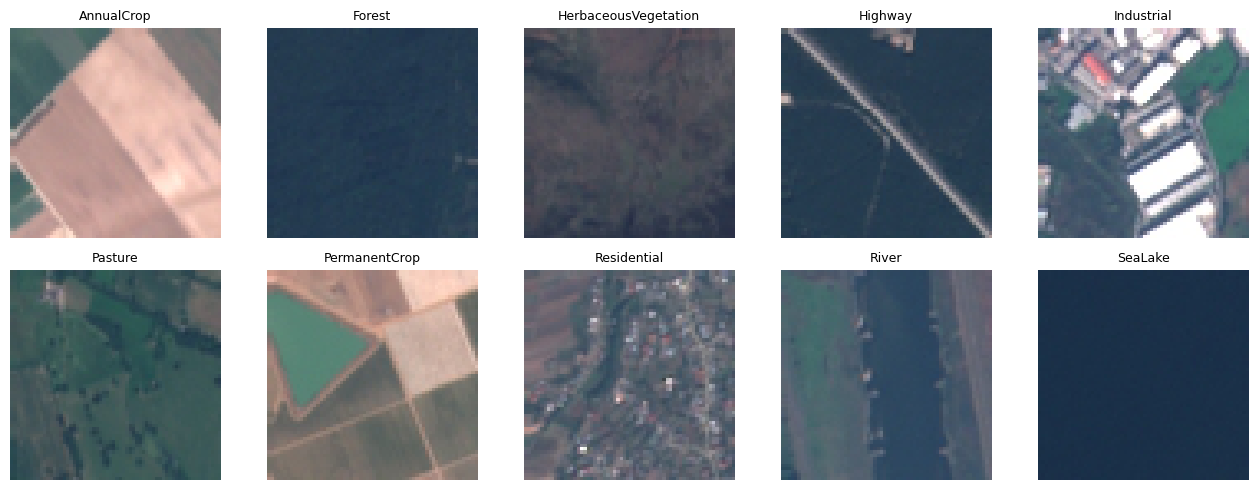

In [4]:
# Visualizamos una imagen por clase del conjunto de entrenamiento, sin aumentos.
preview_dataset = EuroSATDataset(DATA_DIR, train_samples, eval_transform)
fig, axes = plt.subplots(2, 5, figsize=(13, 5))
for label, ax in enumerate(axes.flat):
    idx = next(i for i, (_, y) in enumerate(train_samples) if y == label)
    img, _ = preview_dataset[idx]
    img = img * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]
    ax.imshow(img.permute(1, 2, 0).clamp(0, 1))
    ax.set_title(class_names[label], fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

### CNN propia
Tres bloques de convolución 3 × 3, BatchNorm, ReLU y max pooling aumentan
los canales (32 → 64 → 128) mientras reducen la resolución (64 → 32 → 16 → 8).
BatchNorm ayuda a estabilizar el entrenamiento y dropout regulariza el clasificador.
El promedio espacial global produce un vector de 128 características que podremos
extraer en el punto 2. La última capa devuelve diez **logits**; no aplicamos softmax
porque `CrossEntropyLoss` ya incorpora esa operación de forma estable.
Todos los pesos se inicializan desde cero, sin modelos preentrenados.

In [5]:
class MiCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
        )
        self.dropout = nn.Dropout(0.3)
        self.classifier = nn.Linear(128, num_classes)
        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(module.weight, nonlinearity='relu')

    def forward_features(self, x):
        return self.features(x)

    def forward(self, x):
        return self.classifier(self.dropout(self.forward_features(x)))

model = MiCNN(num_classes).to(device)
print(model)
print('Parámetros entrenables:', sum(p.numel() for p in model.parameters() if p.requires_grad))
model.eval()
with torch.no_grad():
    ejemplo = torch.zeros(2, 3, 64, 64, device=device)
    assert model(ejemplo).shape == (2, num_classes)
    assert model.forward_features(ejemplo).shape == (2, 128)
print('Dimensiones verificadas.')

MiCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): AdaptiveAvgPool2d(output_size=1)
    (13): Flatten(start_dim=1, end_dim=-1)
  )
  (dropout): 

### Entrenamiento y monitoreo de gradientes
Seguimos el loop de las prácticas: `zero_grad → forward → loss → backward → step`.
Calculamos pérdida y accuracy ponderando por cantidad de imágenes, incluido el último
lote incompleto. Validación usa `eval()` y desactiva el cálculo de gradientes.

Durante las primeras tres épocas registramos, **después de backward y antes de step**,
la media absoluta de los gradientes de cada capa convolucional/densa y la norma L2
global por lote. Detenemos la ejecución ante pérdidas o gradientes no finitos.
No recortamos gradientes para no ocultar su magnitud. No hay un umbral universal
que por sí solo diagnostique desvanecimiento o explosión: se observa su evolución,
la relación entre capas y las curvas de aprendizaje.

In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)

def entrenar_una_epoca(model, loader, monitorear=False):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    grad_layers, grad_norms = {}, []
    for images, labels in tqdm(loader, leave=False):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        if not torch.isfinite(loss).item():
            raise RuntimeError('Pérdida no finita; revisar datos y learning rate.')
        loss.backward()

        # También verificamos valores no finitos fuera de las épocas monitoreadas.
        grads = [p.grad for p in model.parameters() if p.grad is not None]
        norm = torch.stack([g.detach().norm(2) for g in grads]).norm(2)
        if not torch.isfinite(norm).item():
            raise RuntimeError('Gradientes no finitos; revisar el entrenamiento.')
        if monitorear:
            grad_norms.append(norm.item())
            for name, p in model.named_parameters():
                if p.grad is not None and p.ndim > 1:
                    grad_layers.setdefault(name, []).append(p.grad.detach().abs().mean().item())
        optimizer.step()

        n = labels.size(0)
        total_loss += loss.item() * n
        correct += (logits.argmax(1) == labels).sum().item()
        total += n
    resumen = {name: float(np.mean(vals)) for name, vals in grad_layers.items()}
    return total_loss / total, 100 * correct / total, resumen, grad_norms

@torch.no_grad()
def evaluar(model, loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        total_loss += criterion(logits, labels).item() * labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, 100 * correct / total

def sincronizar():
    if device.type == 'cuda':
        torch.cuda.synchronize()
    elif device.type == 'mps':
        torch.mps.synchronize()

In [7]:
# Ejecutar esta celda inicia una corrida nueva desde cero.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
generator.manual_seed(SEED)
model = MiCNN(num_classes).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
history = {k: [] for k in ['train_loss', 'val_loss', 'train_acc', 'val_acc', 'seconds']}
gradient_history = []
best_val_loss = float('inf')
best_epoch = None

for epoch in range(1, EPOCHS + 1):
    sincronizar()
    inicio = time.perf_counter()
    train_loss, train_acc, layer_grads, norms = entrenar_una_epoca(
        model, train_loader, monitorear=epoch <= GRAD_EPOCHS)
    val_loss, val_acc = evaluar(model, val_loader)
    if not np.isfinite(val_loss):
        raise RuntimeError('Pérdida de validación no finita.')
    sincronizar()
    seconds = time.perf_counter() - inicio
    for k, value in zip(history, [train_loss, val_loss, train_acc, val_acc, seconds]):
        history[k].append(value)
    if layer_grads:
        gradient_history.append({'epoch': epoch, 'layers': layer_grads, 'norms': norms})
    print(f'Época {epoch:02d}/{EPOCHS} | train loss {train_loss:.4f}, acc {train_acc:.2f}% '
          f'| val loss {val_loss:.4f}, acc {val_acc:.2f}% | {seconds:.1f} s')

    # Selección exclusivamente por validación, sin consultar test.
    if val_loss < best_val_loss:
        best_val_loss, best_epoch = val_loss, epoch
        torch.save({
            'model_state_dict': model.state_dict(),
            'class_names': class_names, 'epoch': epoch,
            'val_loss': val_loss, 'val_acc': val_acc,
            'seed': SEED, 'mean': MEAN, 'std': STD,
        }, OUTPUT_DIR / 'mejor_cnn.pt')
    with (OUTPUT_DIR / 'historial.json').open('w', encoding='utf-8') as f:
        json.dump({'history': history, 'gradients': gradient_history}, f, indent=2)

checkpoint = torch.load(OUTPUT_DIR / 'mejor_cnn.pt', map_location=device, weights_only=True)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print(f"Mejor época: {best_epoch}, val loss: {best_val_loss:.4f}, "
      f"val accuracy: {checkpoint['val_acc']:.2f}%")
print('Se restauraron los mejores pesos. Test queda para el punto 2.')

  0%|          | 0/296 [00:00<?, ?it/s]

Época 01/25 | train loss 1.0386, acc 64.62% | val loss 0.7027, acc 75.67% | 157.8 s


  0%|          | 0/296 [00:00<?, ?it/s]

Época 02/25 | train loss 0.7147, acc 75.08% | val loss 0.6623, acc 76.52% | 164.7 s


  0%|          | 0/296 [00:00<?, ?it/s]

Época 03/25 | train loss 0.6254, acc 78.08% | val loss 0.5078, acc 83.28% | 180.4 s


  0%|          | 0/296 [00:00<?, ?it/s]

Época 04/25 | train loss 0.5784, acc 79.75% | val loss 0.5043, acc 82.74% | 178.3 s


  0%|          | 0/296 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
epochs = np.arange(1, len(history['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for split, label in [('train', 'Entrenamiento'), ('val', 'Validación')]:
    axes[0].plot(epochs, history[f'{split}_loss'], label=label)
    axes[1].plot(epochs, history[f'{split}_acc'], label=label)
axes[0].set(title='Evolución de la pérdida', xlabel='Época', ylabel='Cross entropy')
axes[1].set(title='Evolución del accuracy', xlabel='Época', ylabel='Accuracy (%)')
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'curvas_entrenamiento.png', dpi=160)
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for record in gradient_history:
    names = list(record['layers'])
    values = [record['layers'][name] for name in names]
    # Piso solo para dibujar en escala logarítmica; se conservan ceros en el historial.
    axes[0].plot(range(len(names)), np.maximum(values, 1e-12), marker='o',
                 label=f"Época {record['epoch']}")
    axes[1].plot(record['norms'], label=f"Época {record['epoch']}")
    print(f"Época {record['epoch']}: norma L2 min={min(record['norms']):.3g}, "
          f"media={np.mean(record['norms']):.3g}, max={max(record['norms']):.3g}")
axes[0].set_xticks(range(len(names)), names, rotation=35, ha='right')
axes[0].set_yscale('log')
axes[0].set(title='Flujo de gradientes por capa', ylabel='Media de |gradiente| por lote')
axes[1].set(title='Norma L2 global antes del paso', xlabel='Lote dentro de la época', ylabel='Norma L2')
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'gradientes.png', dpi=160)
plt.show()

### Interpretación para el informe (completar con la ejecución)
- Registrar la época elegida y su pérdida y accuracy de validación.
- Comparar las curvas: si train sigue mejorando pero val empeora de forma sostenida,
  hay indicios de sobreajuste. El accuracy de train se mide con aumentos y dropout
  activos; por eso no es directamente equivalente a validación.
- Revisar si los gradientes de las primeras capas se mantienen persistentemente
  cerca de cero respecto de las últimas, junto con falta de aprendizaje; eso puede
  indicar desvanecimiento. Picos crecientes, inestabilidad o valores no finitos
  pueden indicar explosión. Un gráfico finito por sí solo no prueba ausencia del problema.
- Reportar el dispositivo y el tiempo por época. El tiempo registrado incluye
  entrenamiento, validación y monitoreo; las primeras tres épocas tienen ese costo extra.
- No reportar métricas de test hasta el punto 2 ni usarlas para elegir hiperparámetros.

Se guardan los mejores pesos, el historial y las figuras en `resultados_punto1`.
Los resultados numéricos quedan pendientes hasta ejecutar el notebook con PyTorch.